### Exercice 14 — Détection d'anomalies

In [17]:
import numpy as np

import pandas as pd

from sklearn.ensemble import IsolationForest

from sklearn.metrics import confusion_matrix , ConfusionMatrixDisplay

import matplotlib.pyplot as plt

### Generation du dataset

In [18]:
n = 5000

n_anomalies = int( n * 0.045)

n_normales = n - n_anomalies

df = pd.DataFrame({

    "montant_transaction": np.clip(

        np.random.lognormal(np.log(50), 0.8, n_normales),

        1, 500
    ),

    "heure_transaction": np.random.randint(7, 23, n_normales),

    "nb_transactions_dernieres_24h": np.random.poisson(3, n_normales),

    "distance_domicile_km": np.random.exponential(5, n_normales)
})

df

,montant_transaction,heure_transaction,nb_transactions_dernieres_24h,distance_domicile_km
0,15.114680,17,3,9.537259
1,42.957272,8,1,6.217493
2,36.773379,7,2,2.418041
3,40.132540,20,1,1.062065
4,106.339575,11,1,3.422246
...,...,...,...,...
4770,32.930851,21,4,2.090793
4771,49.599458,22,4,3.471439
4772,18.414010,10,5,2.295331
4773,17.476444,8,2,7.755693


### Injection des valaur d'anomalie

In [19]:
df["est_anomalie_reelle"] = 0

anomalies = pd.DataFrame({

    "montant_transaction": np.random.uniform(

        2000, 10000, n_anomalies
    ),

    "heure_transaction": np.random.randint(

        0, 6, n_anomalies
    ),

    "nb_transactions_dernieres_24h": np.random.randint(

        8, 20, n_anomalies
    ),

    "distance_domicile_km": np.random.uniform(

        200, 1000, n_anomalies
    ),

    "est_anomalie_reelle": 1
})

df = pd.concat(

    [df, anomalies],

    ignore_index=True
)

df = df.sample(

    frac=1,

    random_state=42

).reset_index(drop=True)

df

,montant_transaction,heure_transaction,nb_transactions_dernieres_24h,distance_domicile_km,est_anomalie_reelle
0,39.578084,16,2,0.351976,0
1,36.969877,22,6,0.370781,0
2,271.502710,21,6,1.948598,0
3,52.073827,7,1,1.788421,0
4,22.775648,15,4,1.716895,0
...,...,...,...,...,...
4995,74.834105,14,3,8.040672,0
4996,32.158559,21,2,5.335224,0
4997,57.682393,7,1,5.086621,0
4998,132.489392,16,5,2.384714,0


In [20]:
x = df.drop(["est_anomalie_reelle"] , axis=1)

y  = df["est_anomalie_reelle"]

### Entrainement du model d'isolation forest

In [46]:
model = IsolationForest(contamination=0.045, random_state=42)

model.fit(x)

pred =  model.predict(x)

pred_or =  np.array(pred)

### Convertion en 0/1

In [47]:
pred = np.where(pred_or == -1, 1, 0)


### Visualisation des montants en foction des heures

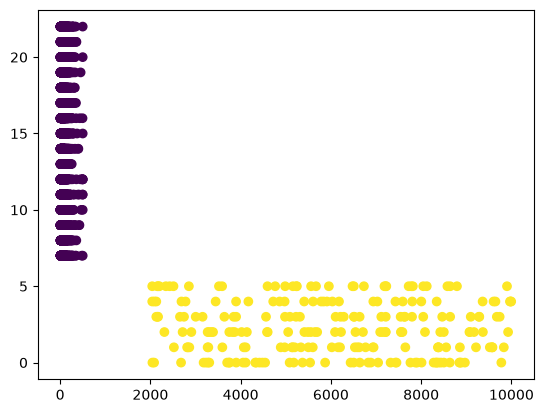

In [48]:
fig , ax =  plt.subplots()

ax.scatter(x["montant_transaction"] , x["heure_transaction"] ,c=pred)

### Comparaison des prédictions à est_anomalie_reelle avec une matrice de confusion, et calcule précision/rappel spécifiquement pour la classe "anomalie"

In [49]:
cm =  confusion_matrix(y,pred)

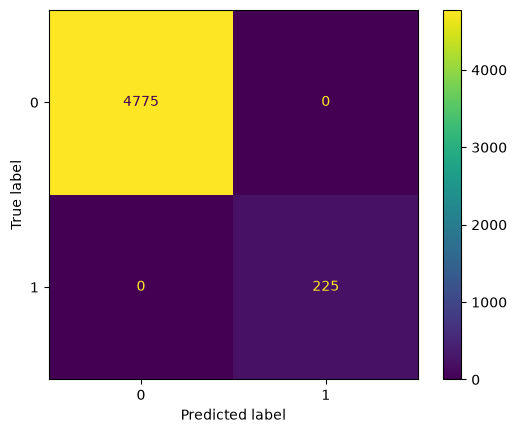

In [55]:
ConfusionMatrixDisplay(cm).plot()